In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
# from utils import ...

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
cell_lines = list(cell_line_dict.values())

TEMPDIR = Path(config['TEMPDIR'])

# Which guides are truly transcript-specific?

Problem: 
We have guides that are supposedly targeting a specific transcript of a gene.
However, we find the same sequence of the guide in multiple transcripts, which is apparent:
- when we compare the results from annotating the guides against the genome or the transcriptome.
- when looking at the guide sequences suggested by Sanjana lab (they were overlapping between transcripts, so cannot be unique to a transcript).

Goal:
The goal is to identify the guides that are truly specific to a transcript.

Approach:
- We can check if the guide aligns to multiple transcripts. (do this)
- We could export all top guides from the Sanjana lab and check if they are unique to a transcript. (bad idea)

In [2]:
def parse_sam_file(sam_file):
    data = []
    with open(sam_file, 'r') as f:
        for line in f:
            # Skip header lines if any
            if line.startswith('@'):
                continue
            
            fields = line.strip().split('\t')
            # Extract relevant fields
            query_name = fields[0]
            flag = int(fields[1])
            reference_name = fields[2]
            position = int(fields[3])
            mapq = int(fields[4])
            cigar = fields[5]
            rnext = fields[6]
            pnext = int(fields[7])
            tlen = int(fields[8])
            seq = fields[9]
            qual = fields[10]
            # Additional optional fields
            optional_fields = fields[11:]
            # Store the information
            data.append({'QueryName': query_name, 'Flag': flag, 'ReferenceName': reference_name, 'Position': position,
                         'MappingQuality': mapq, 'CIGAR': cigar, 'RNext': rnext, 'PNext': pnext, 'TLEN': tlen,
                         'Sequence': seq, 'Quality': qual, 'OptionalFields': optional_fields})
    return data

# Define a dictionary mapping tag abbreviations to descriptive names
TAG_DESCRIPTIONS = {
    'AS': 'Alignment score',
    'XN': 'Number of ambiguous bases',
    'XM': 'Number of mismatches',
    'XO': 'Number of gap opens',
    'XG': 'Number of gap extensions',
    'NM': 'Edit distance to the reference',
    'MD': 'String for mismatching positions',
    'YT': 'Type of read',
    'NH': 'Number of reported alignments'
    # Add other tag descriptions as needed
}

def parse_optional_fields(optional_fields):
    """
    Parse a list of optional fields from a SAM file into a dictionary.

    Args:
        optional_fields (list): A list of strings representing the optional fields in a SAM file.

    Returns:
        dict: A dictionary where the keys are the tag names and the values are the tag values.
    """
    parsed_fields = {}
    
    for field in optional_fields:
        tag, type_and_value = field.split(':', 1)
        tag_name = TAG_DESCRIPTIONS[tag] if tag in TAG_DESCRIPTIONS else tag
        type_, value = type_and_value.split(':', 1)
        
        # Convert the value to the appropriate type
        if type_ == 'i':
            value = int(value)
        elif type_ == 'f':
            value = float(value)
        # For 'Z' (string) and 'H' (hex string), keep as string
        # so no conversion needed
        
        parsed_fields[tag_name] = value
    
    return parsed_fields

def process_alignment(sam_path, keep_duplicates=False):
    alignment = pd.DataFrame(parse_sam_file(sam_path)).set_index('QueryName')

    # Annotate strand
    alignment['strand'] = None
    alignment['strand'][(alignment['Flag'] == 16) | (alignment['Flag'] == 272)] = '-'
    alignment['strand'][(alignment['Flag'] == 0) | (alignment['Flag'] == 256)] = '+'
    # Parse optional fields and add as columns
    optFields = pd.DataFrame(alignment['OptionalFields'].apply(parse_optional_fields).values.tolist(), index=alignment.index)
    alignment = pd.concat([alignment, optFields], axis=1)
    
    # Remove and rename columns
    alignment.drop(['RNext', 'PNext', 'TLEN', 'OptionalFields'], inplace=True, axis=1)
    alignment.rename(columns={'ReferenceName': 'chromosome', 'Position': 'Start_position'}, inplace=True)
    alignment.index.name = 'guide_id'
    # Calculate end position
    alignment['End_position'] = alignment['Start_position'] + alignment['Sequence'].str.len()
    # Remove unmapped reads
    alignment = alignment[alignment['Flag'] != 4]

    alignment = alignment.sort_values('MappingQuality', ascending=False)
    salignment = alignment if keep_duplicates else alignment[~alignment.index.duplicated(keep='first')]
    guide_df = pd.read_csv('../resources/all_gRNA_data.csv', index_col='unique_guide_name')
    tab = pd.merge(guide_df, salignment, left_index=True, right_index=True, how='left')
    
    return tab

In [3]:
# Keep multiple alignments
tab_rna = process_alignment(TEMPDIR / "pooled_screen_1/hisat2/guides_aligned_to_transcriptome.sam", True)

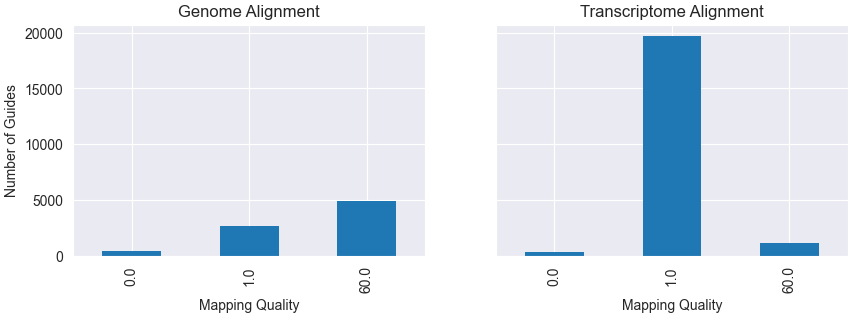

In [4]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharey=True)
ax = axs[0]
tab_rna.MappingQuality.fillna(0).value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_title('Genome Alignment')
ax.set_ylabel('Number of Guides')

ax = axs[1]
tab_rna.MappingQuality.fillna(0).value_counts().sort_index().plot(kind='bar')
ax.set_title('Transcriptome Alignment')

for ax in axs:
    ax.set_xlabel('Mapping Quality')
    ax.grid(True)
pl.show()

In [5]:
tab_rna['alignment_transcriptID'] = tab_rna.chromosome.str.split('|').str[0].str.split('.').str[0]
tab_rna['alignment_on_target_transcript'] = tab_rna['alignment_transcriptID'] == tab_rna.Transcript_ID
tab_rna['alignment_gene'] = tab_rna.chromosome.str.split('|').str[5]
tab_rna['alignment_gene_id'] = tab_rna.chromosome.str.split('|').str[1].str.split('.').str[0]
tab_rna['alignment_on_target_gene'] = tab_rna['alignment_gene_id'] == tab_rna.ensembl_gene_id

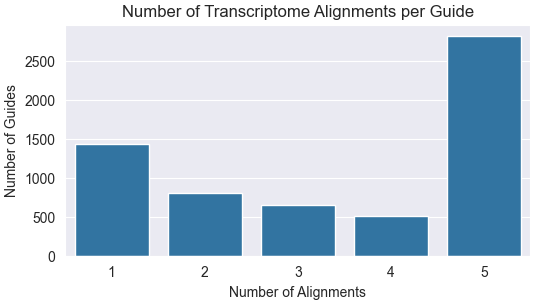

In [6]:
# How many guide have multiple alignments?
cts = tab_rna.groupby(tab_rna.index).size().value_counts().sort_index()

with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6, 3))
    sns.barplot(x=cts.index, y=cts, color='tab:blue', ax=ax)
pl.xlabel('Number of Alignments')
pl.ylabel('Number of Guides')
pl.title('Number of Transcriptome Alignments per Guide')
pl.show()

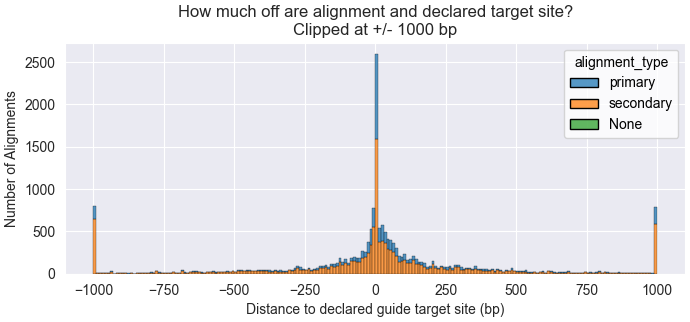

In [7]:
tab_rna['GuideName_start'] = tab_rna.GuideName.str.split(':').str[1].str.split('-').str[0]
tab_rna['GuideName_end'] = tab_rna.GuideName.str.split(':').str[1].str.split('-').str[1]
tab_rna.GuideName_start = [int(x) if x == x else np.nan for x in tab_rna.GuideName_start]
tab_rna.GuideName_end = [int(x)+1 if x == x else np.nan for x in tab_rna.GuideName_end]
tab_rna['offset'] = tab_rna.GuideName_start - tab_rna.Start_position
tab_rna['alignment_type'] = ['None' if flag!=flag else 'primary' if flag <=16 else 'secondary' for flag in tab_rna.Flag]

n_clip = 1000
df = tab_rna.copy()
df.offset = df.offset.clip(-n_clip, n_clip)
df.reset_index(inplace=True)
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(8, 3))
sns.histplot(data=df, x='offset', bins=200, hue='alignment_type', multiple='stack')
pl.title(f'How much off are alignment and declared target site?\nClipped at +/- {n_clip} bp')
pl.ylabel('Number of Alignments')
pl.xlabel('Distance to declared guide target site (bp)')
pl.show()

In [8]:
# How many alignments are within the same gene and how many are in the same transcript?
tab_rna['alignment_site'] = 'different genes'
tab_rna['alignment_site'][tab_rna['alignment_transcriptID'].isna()] = 'no alignment'
tab_rna['alignment_site'][tab_rna['alignment_on_target_gene']] = 'same gene, different transcript'
tab_rna['alignment_site'][tab_rna['alignment_on_target_transcript']] = 'same transcript, different target site'
tab_rna['alignment_site'][np.abs(tab_rna['offset'])<=1] = 'same target site'
class_dict={
    'no alignment': -1,
    'different genes': 0, 
    'same gene, different transcript': 1, 
    'same transcript, different target site': 2, 
    'same target site': 3}
tab_rna['alignment_site_class'] = tab_rna['alignment_site'].map(class_dict)

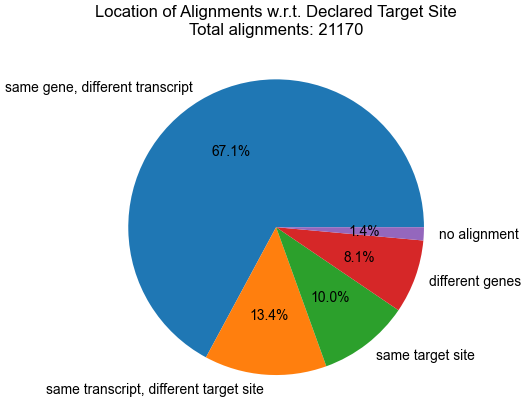

In [9]:
cts = tab_rna['alignment_site'].value_counts()
pl.pie(cts, labels=cts.index, autopct='%1.1f%%')
pl.title(f'Location of Alignments w.r.t. Declared Target Site\nTotal alignments: {cts.sum()}')
pl.show()

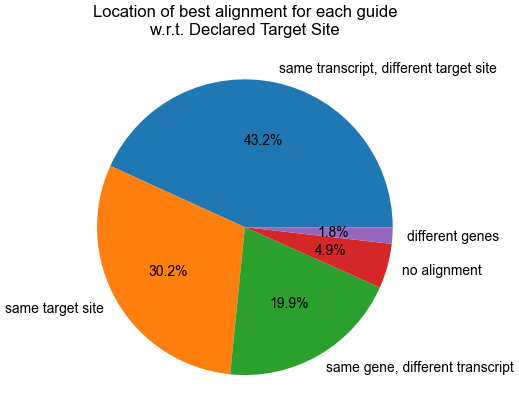

In [10]:
# Best alignment for each guide
X = tab_rna.reset_index().value_counts(['index', 'alignment_site_class'], sort=False).unstack().fillna(0)
flipped_class_dict = {v: k for k, v in class_dict.items()}
best_class = tab_rna.reset_index().value_counts(['index', 'alignment_site_class'], sort=False).reset_index().drop(0, axis=1).groupby('index').max()
best_class_label = best_class.alignment_site_class.map(flipped_class_dict)
assert len(best_class_label) == 6225

cts = best_class_label.value_counts()
pl.pie(cts, labels=cts.index, autopct='%1.1f%%')
pl.title('Location of best alignment for each guide\nw.r.t. Declared Target Site')
pl.show()

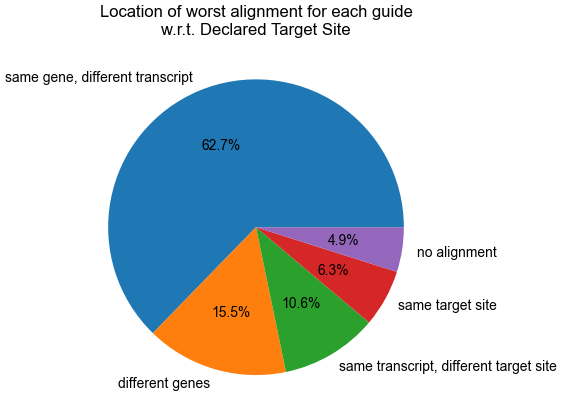

In [11]:
# Worst alignment for each guide
X = tab_rna.reset_index().value_counts(['index', 'alignment_site_class'], sort=False).unstack().fillna(0)
flipped_class_dict = {v: k for k, v in class_dict.items()}
best_class = tab_rna.reset_index().value_counts(['index', 'alignment_site_class'], sort=False).reset_index().drop(0, axis=1).groupby('index').min()
best_class_label = best_class.alignment_site_class.map(flipped_class_dict)
assert len(best_class_label) == 6225

cts = best_class_label.value_counts()
pl.pie(cts, labels=cts.index, autopct='%1.1f%%')
pl.title('Location of worst alignment for each guide\nw.r.t. Declared Target Site')
pl.show()

# Converting things to BED format for visualization

Things to convert:
- Guide positions (claimed)
- Guide positions (alignments)

In [12]:
class_dict

{'no alignment': -1,
 'different genes': 0,
 'same gene, different transcript': 1,
 'same transcript, different target site': 2,
 'same target site': 3}

In [13]:
tab_rna_sub = tab_rna[tab_rna.alignment_site_class.isin([1, 2, 3])].reset_index()

In [24]:
# convert to bed format
bed_df = tab_rna_sub[['chromosome', 'Start_position', 'End_position', 'index', 'strand']]
bed_df['score'] = 1000
bed_df.columns = ['chrom', 'start', 'end', 'name', 'strand', 'score']
bed_df = bed_df[['chrom', 'start', 'end', 'name', 'score', 'strand']]
bed_df.start = bed_df.start.astype(int).astype(str)
bed_df.end = bed_df.end.astype(int).astype(str)
bed_df = bed_df[bed_df.name.duplicated(keep=False)]  # take only multiple alignments

In [25]:
bed_df.head()

,chrom,start,end,name,score,strand
6,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,3378,3401,AATBC_ENST00000400385_3400,1000,-
7,ENST00000448247.5|ENSG00000215458.8|OTTHUMG000...,393,416,AATBC_ENST00000400385_3400,1000,-
8,ENST00000448247.5|ENSG00000215458.8|OTTHUMG000...,1091,1114,AATBC_ENST00000400385_3822,1000,-
9,ENST00000437258.5|ENSG00000215458.8|OTTHUMG000...,134,157,AATBC_ENST00000400385_3822,1000,-
10,ENST00000400385.2|ENSG00000215458.8|OTTHUMG000...,3800,3823,AATBC_ENST00000400385_3822,1000,-


In [26]:
list(bed_df.chrom)

['ENST00000400385.2|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195677.1|AATBC-201|AATBC|4598|lncRNA|',
 'ENST00000448247.5|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195676.1|AATBC-203|AATBC|1889|lncRNA|',
 'ENST00000448247.5|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195676.1|AATBC-203|AATBC|1889|lncRNA|',
 'ENST00000437258.5|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195678.1|AATBC-202|AATBC|932|lncRNA|',
 'ENST00000400385.2|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195677.1|AATBC-201|AATBC|4598|lncRNA|',
 'ENST00000400385.2|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195677.1|AATBC-201|AATBC|4598|lncRNA|',
 'ENST00000448247.5|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195676.1|AATBC-203|AATBC|1889|lncRNA|',
 'ENST00000437258.5|ENSG00000215458.8|OTTHUMG00000086882.1|OTTHUMT00000195678.1|AATBC-202|AATBC|932|lncRNA|',
 'ENST00000442925.5|ENSG00000144648.16|OTTHUMG00000186377.5|OTTHUMT00000343739.2|ACKR2-202|ACKR2|2879|protein_codi

In [27]:
# Note: due to some bug I manually have to remove the trailing .0 from all numbers...
bed_df.to_csv(TEMPDIR / 'pooled_screen_1/igv/alignments.bed', sep='\t', index=False, header=False)

# Instead, take genome alignments and check if the guide aligns to multiple transcripts

In [32]:
# I think for this it might make more sense to use the genome alignment?
tab_dna = process_alignment(TEMPDIR / "pooled_screen_1/hisat2/guides_aligned_to_genome.sam", True)

In [33]:
tab_rna

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,ZS,Number of ambiguous bases,Number of mismatches,Number of gap opens,Number of gap extensions,Edit distance to the reference,String for mismatching positions,Type of read,Number of reported alignments,End_position
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,1006.0
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,1563.0
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,1939.0
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,2714.0
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSWIM3_ENST00000255152_164,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0142:142-164,CAAGATCACACCAGGGGTCAAAG,164.0,0.956957,UTR5,2776.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,168.0
ZSWIM3_ENST00000255152_2431,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2370:2409-2431,TGTAACAATATTCCTAGCCCCAC,2431.0,1.329908,UTR3,2776.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,2435.0
ZSWIM3_ENST00000255152_2528,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2467:2506-2528,TGAACAACAACTGAGGCTCCCAA,2528.0,1.386289,UTR3,2776.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,2532.0
ZSWIM3_ENST00000255152_32,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0010:10-32,GTTACAAGAGGAAGGGGGTGTAT,32.0,0.860280,UTR5,2776.0,...,NaN,0.0,0.0,0.0,0.0,0.0,23,UU,1.0,36.0


In [42]:
# Load annotation (buffered)
if not (TEMPDIR / 'pooled_screen_1/igv/gencode.v45.annotation.csv').exists():
    from gtfparse import read_gtf
    gtf_ = read_gtf(TEMPDIR / 'pooled_screen_1/igv/gencode.v45.annotation.gtf')
    gtf = pd.DataFrame(gtf_, columns=gtf_.columns)
    gtf.to_csv(TEMPDIR / 'pooled_screen_1/igv/gencode.v45.annotation.csv', index=False)
else:
    # Buffer
    gtf = pd.read_csv(TEMPDIR / 'pooled_screen_1/igv/gencode.v45.annotation.csv')

INFO:root:Extracted GTF attributes: ['gene_id', 'gene_type', 'gene_name', 'level', 'tag', 'transcript_id', 'transcript_type', 'transcript_name', 'transcript_support_level', 'havana_transcript', 'exon_number', 'exon_id', 'hgnc_id', 'havana_gene', 'ont', 'protein_id', 'ccdsid', 'artif_dupl']


In [43]:
gtf

,seqname,source,feature,start,end,score,strand,frame,gene_id,gene_type,...,transcript_support_level,havana_transcript,exon_number,exon_id,hgnc_id,havana_gene,ont,protein_id,ccdsid,artif_dupl
0,chr1,HAVANA,gene,11869,14409,NaN,+,0,ENSG00000290825.1,lncRNA,...,,,,,,,,,,
1,chr1,HAVANA,transcript,11869,14409,NaN,+,0,ENSG00000290825.1,lncRNA,...,1,OTTHUMT00000362751.1,,,,,,,,
2,chr1,HAVANA,exon,11869,12227,NaN,+,0,ENSG00000290825.1,lncRNA,...,1,OTTHUMT00000362751.1,1,ENSE00002234944.1,,,,,,
3,chr1,HAVANA,exon,12613,12721,NaN,+,0,ENSG00000290825.1,lncRNA,...,1,OTTHUMT00000362751.1,2,ENSE00003582793.1,,,,,,
4,chr1,HAVANA,exon,13221,14409,NaN,+,0,ENSG00000290825.1,lncRNA,...,1,OTTHUMT00000362751.1,3,ENSE00002312635.1,,,,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3427472,chrM,ENSEMBL,transcript,15888,15953,NaN,+,0,ENSG00000210195.2,Mt_tRNA,...,NA,,,,HGNC:7499,,,,,
3427473,chrM,ENSEMBL,exon,15888,15953,NaN,+,0,ENSG00000210195.2,Mt_tRNA,...,NA,,1,ENSE00001544475.2,HGNC:7499,,,,,
3427474,chrM,ENSEMBL,gene,15956,16023,NaN,-,0,ENSG00000210196.2,Mt_tRNA,...,,,,,HGNC:7494,,,,,
3427475,chrM,ENSEMBL,transcript,15956,16023,NaN,-,0,ENSG00000210196.2,Mt_tRNA,...,NA,,,,HGNC:7494,,,,,


In [48]:
# where is the gene?
tab_dna

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,Number of mismatches,Number of gap opens,Number of gap extensions,Edit distance to the reference,String for mismatching positions,Type of read,Number of reported alignments,ZS,XS,End_position
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,43811586.0
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,43811029.0
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,43810653.0
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,43809878.0
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,43812563.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSWIM3_ENST00000255152_164,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0142:142-164,CAAGATCACACCAGGGGTCAAAG,164.0,0.956957,UTR5,2776.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,45857781.0
ZSWIM3_ENST00000255152_2431,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2370:2409-2431,TGTAACAATATTCCTAGCCCCAC,2431.0,1.329908,UTR3,2776.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,45878781.0
ZSWIM3_ENST00000255152_2528,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA2467:2506-2528,TGAACAACAACTGAGGCTCCCAA,2528.0,1.386289,UTR3,2776.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,45878878.0
ZSWIM3_ENST00000255152_32,ENST00000255152,ENSG00000132801,ZSWIM3,protein_coding,crRNA0010:10-32,GTTACAAGAGGAAGGGGGTGTAT,32.0,0.860280,UTR5,2776.0,...,0.0,0.0,0.0,0.0,23,UU,1.0,NaN,NaN,45857649.0


In [ ]:
# tab_rna['alignment_transcriptID'] = tab_rna.chromosome.str.split('|').str[0].str.split('.').str[0]
# tab_rna['alignment_on_target_transcript'] = tab_rna['alignment_transcriptID'] == tab_rna.Transcript_ID
tab_rna['alignment_gene'] = tab_rna.chromosome.str.split('|').str[5]
tab_rna['alignment_gene_id'] = tab_rna.chromosome.str.split('|').str[1].str.split('.').str[0]
tab_rna['alignment_on_target_gene'] = tab_rna['alignment_gene_id'] == tab_rna.ensembl_gene_id